# Phase 0: Libraries and Starting Variables

Cell 1 is configuring the baseline, calling the libraries and setting up the variables necessary to work with the data set generation built in Cell 2. The boring, but very necessary stuff.

In [1]:
import numpy as np
import pandas as pd
from itertools import product
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(50)

#Building the variables and columns
SKUs = [f"SKU-{i:05d}" for i in range(1,1401)]
LOCATIONS = ["STG-A", "STG-B", "STG-C", "PICK-1", "PICK-2"]
TIME_FRAME = pd.period_range("2025-01", "2026-10", freq="M")
types = ["shrink", "surplus", "zero count", "data entry"]


---

# Phase 1: Data Generation

This is where we begin the data generation.  First, setting a baseline quantity(physical inventory), adding usage throughout the year (noise), and some small amount of inventory drift to simulate human error as the year progresses through.

For synthetic data, this is important to simulate as we could model a "perfect world" where nothing is wrong, but that would skew the separation between anomalous SKUs and good SKUs.

In [2]:
#Generating the data
records = []
for sku in SKUs:
    base_qty = rng.integers(50,500)
    noise = rng.uniform(.03,.08)
    drift = rng.normal(0,.02)

    for loc in LOCATIONS:
        for period in TIME_FRAME:
            qty_last = int(base_qty * rng.normal(1, noise))
            qty_current = int(base_qty * (1+drift) * rng.normal(1,noise))
            records.append({
                "sku": sku,
                "location": loc,
                "period": str(period),
                "count_qty_prior_year": max(qty_last,0),
                "count_qty_current_year": max (qty_current,0)
                    })
df = pd.DataFrame(records)
df["yoy_variance"] = ((df["count_qty_current_year"] - df["count_qty_prior_year"]) / df["count_qty_prior_year"].replace(0, np.nan))

This is where we inject the anomalies into the data, as well as capture, what I have lovingly called the "answer key" in this demonstration.

For those that just want to see the good stuff, you can continue on to the next header; however, if you're curious about the inner machinations of the code, this is how this cell works:

## Code Explained:

First we define a mask boolean array that generates a random number between 0 and 1 (not including 1), and assign either true or false to each row by asking the question, "Is this value less than .015?"

Next, we tell the code to choose between various choices (defined in Cell 1) with the same size as the boolean array we just constructed (**VERY IMPORTANT**).  We assign a weight to each value, here we have a weight of 40%, 25%, 20%, and 15% for each string in the types array.  This mixes the anomalies around so we don't explicitly know which rows have which anomalies, just that the rows are anomalous.

Now the rest is telling the code what to do, that is, based on the weights previously stated, and the types that we defined, go through each row in the mask array and if true, choose a type, then replace appropriate quantities with a multiple of a random number that correlates with that anomaly type.

Finally, we create an array that acts as our answer key, this is what we check against to check the code.  This can be replicated in the real world with labeled data, but takes time to build.

## Sanity Checking

Once we inject the anomalies, it's good to test to make sure that the rows did, in fact, change.  This is where the Sanity Checks cell comes into play.  I compare the mask to the answer key, and if the two match, we're in business.  If not.... something went horribly wrong!

In [3]:
#Injecting anomalies
anomaly_mask = rng.random(len(df)) < .015
inject_types = rng.choice(types, size=anomaly_mask.sum(), p=[.4,.25,.2,.15])
for i, kind in zip(df.index[anomaly_mask], inject_types):
    if kind == "shrink":
        df.loc[i, "count_qty_current_year"] = int(df.loc[i, "count_qty_prior_year"] * rng.uniform(.35,.6))
    elif kind == "surplus":
        df.loc[i, "count_qty_current_year"] = int(df.loc[i, "count_qty_prior_year"] * rng.uniform(1.8,3.2))
    elif kind == "zero count":
        df.loc[i, "count_qty_current_year"] = 0
    else:
        df.loc[i, "count_qty_current_year"] = int(str(df.loc[i, "count_qty_current_year"]) + "0")

df["yoy_variance"] = ((df["count_qty_current_year"] - df["count_qty_prior_year"]) / df["count_qty_prior_year"].replace(0,np.nan))

#Set the answer key
answer_key = df.index[anomaly_mask]

In [4]:
#Sanity Checks
print(f"Rows: {len(df):,} | Unique SKUs: {df['sku'].nunique()}")
print(f"Anomalies injected: {int(anomaly_mask.sum())}" f" rows ({100*anomaly_mask.mean():.1f}%)")
print(f"'Answer Key' length (should match anomalous rows):{len(answer_key)}")

#Does variance reflect injections?
post_inject_var = ((df["count_qty_current_year"] - df["count_qty_prior_year"]) / df["count_qty_prior_year"].replace(0, np.nan))
assert np.allclose(post_inject_var.dropna(), df["yoy_variance"].dropna()), "yoy_variance does not match post injection!"



Rows: 154,000 | Unique SKUs: 1400
Anomalies injected: 2306 rows (1.5%)
'Answer Key' length (should match anomalous rows):2306


---

# Phase 2: Sanity Checks - Separability

The first histogram below gives us, at a quick glance, a very important detail.  What is that, you may ask? It allows us to answer the question "Can we separate anomalies from noise?" and here, most definitely.

If there were heavy overlap, there would be no real way to separate the anomalies from the true inventory.  Essentially, we wouldn't be able to meaningfully separate the anomalous data from the safe data, and a physical count of ***everything*** would be necessary.

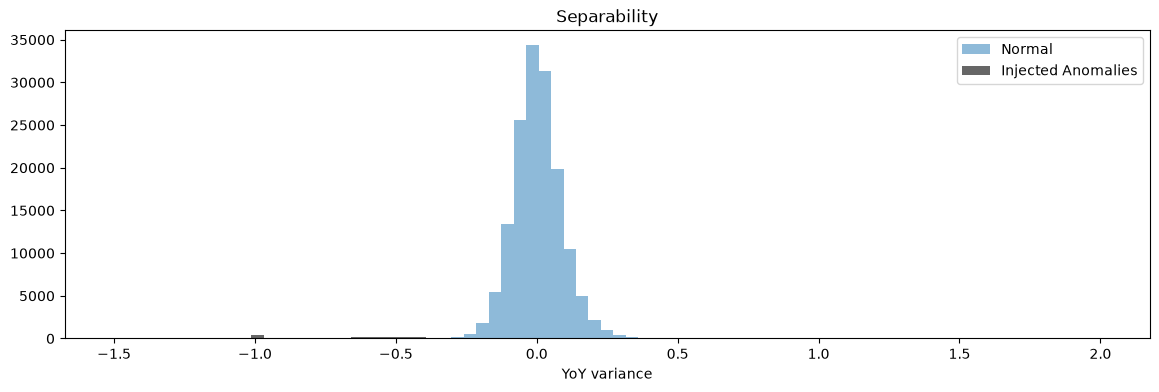

Sanity check complete: anomalies injected successfully.


In [5]:
#Creating histogram for visual anomaly injection confirmation
fig1, ax1 = plt.subplots(figsize=(14, 4))
bins1 = np.linspace(-1.5, 2, 80)
ax1.hist(df.loc[~anomaly_mask, "yoy_variance"].dropna(), bins=bins1, alpha=.5, label="Normal",)
ax1.hist(df.loc[anomaly_mask, "yoy_variance"].dropna(), bins=bins1, alpha=.6, label = "Injected Anomalies", color='black')
ax1.set_xlabel("YoY variance")
ax1.set_title("Separability")
ax1.legend()

plt.show()

if int(anomaly_mask.sum()) > 0:
    print("Sanity check complete: anomalies injected successfully.")
elif int(anomaly_mask.sum()) == 0:
    print("Sanity check complete: anomalies were NOT injected.")
else:
    print("Sanity check complete: something went horribly wrong...")
    


Looking at the histogram, you can see there is a clear divide at about the -.25 mark.  This allows us to extrapolate a baseline to start our search.  Something to keep in mind, however, is this histogram does not show the full picture.  We know that entry errors can happen, such as an extra number at the end of the count entry that doesn't get caught.  That kind of data anomaly is missing from this histogram, as the scaling is slightly off.  Adjusting the scale of the y-axis and extending the x-axis scale to 12, we can see a much clearer picture of what is going on.  

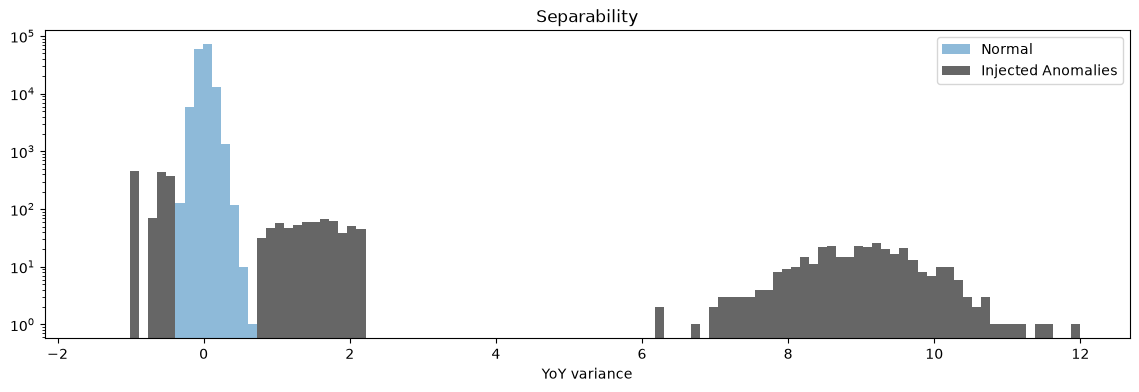

In [6]:
fig2, ax2 = plt.subplots(figsize=(14, 4))
bins2 = np.linspace(-1.5, 12, 110)
ax2.hist(df.loc[~anomaly_mask, "yoy_variance"].dropna(), bins=bins2, alpha=.5, label="Normal",)
ax2.hist(df.loc[anomaly_mask, "yoy_variance"].dropna(), bins=bins2, alpha=.6, label = "Injected Anomalies", color='black')
ax2.set_xlabel("YoY variance")
ax2.set_title("Separability")
ax2.set_yscale("log")
ax2.legend()

plt.show()

Now we can see that not only do we have our initial anomalies that we saw on the original scale, but also that there were also "hidden" anomalies that did not show due to scale.  So what?  Why does this matter?  Well, now we know that we *cannot* simply check for anomalies *below* the curve, we also have to set an upper band that can also capture the anomalies above the normal curve as well.

---

# Phase 3: Anomaly Detection

This is the bread and butter of the code. Inventory discrepancies, no matter the type, inherently contain metric similarities between them.  They could be entered as a 0 count, there is a variance formula and that value could fall outside of an "acceptable drift" range, there could be a SKU in which holds low quantities, which make percentage based analysis useless, and much more.  Here I focused on three of those categories:

First we set a zero checker, it does what the name suggests: checks for values of 0 in the data.

Then we set a variance band.  Basically, is our variance calculation outside of our colloquially accepted drift value?

Next we set up a minimum quantity to keep low count stock out of our sights, since we are evaluating inventory based on a percentage change.  This does come at a cost, though, as we lose high value SKUs this way.  A way to bypass that would be to evaluate **value** as well as the variance band and 0 check.  In this demonstration, to keep it simple, I opted out of also accounting for that.



In [7]:
#Anomaly Detection

#Set 0 checker
zerocheck = df["count_qty_current_year"] == 0

#Set variance band
vlow = -0.25
vhigh = 0.25
vflag = ((df["yoy_variance"] < vlow) | (df["yoy_variance"] > vhigh))

#Exclude small count skus
minqty = 50
floor = (df["count_qty_prior_year"] + df["count_qty_current_year"]) >= minqty

#Set the combined detection
detector = zerocheck | (vflag & floor)

#Create a dataframe for the anomalous rows
anomalies = df[detector].copy()


# Function Definitions

Why have functions at all?  This allows us to analyze the data at any point without having to write the code.  These functions tell us how well the code and parameters we set are working and without them, we would not be able to identify if where we are looking is optimal, or if there are going to be false positives.  This needs to be addressed, as in this demonstration, and across various warehouses and distribution centers, there aren't just 1000 rows of data, it's 154,000.  Small percentages add up *very* quickly in these orders of magnitude.

## What Metrics Are Tracked?

I decided to go with three machine learning metrics: Precision, Recall, and F1.  They each, in this demonstration, answer a different question:

**Precision:** out of all of the rows detected, how many were truly anomalous rows?

**Recall:** Are there any anomalous rows *outside* of the window?

**F1 (Harmonic Mean):** Do the previous two metrics balance nicely, or is one overtaking the other (in either direction)?

## What Is The Purpose of F1?

To get to the purpose of F1, we would need to talk about precision and recall as well, as it's a metric of *both* of them.

Imagine you are using a net to catch fish in a pond that has 100 fish total.  You cast the net and when you pull it back, you have 10 fish and no debris or junk.  That puts your precision at 100%!  That looks great!  But before your bubble forms for me to pop, let's take a look at Recall.  Out of the total 100 fish you *could* have caught, you only caught 10.  That puts your recall at 10%.

Now let's think about the F1 score.  given this scenario, we have perfect precision, but an atrocious recall score, so what would the F1 score look like?  Since F1 is a measure of how well precision and recall work *together*, the score is low.  18% low.  

In [8]:
#Calculating metrics
def detectionMetrics(answer_key_indices, detector_series):
    
    #boolean masks to compare against
    ak_set = set(answer_key_indices)
    det_set = set(detector_series[detector_series].index)

    #Confusion matrix: setting the true/false positives/negative
    tp = len(ak_set & det_set)
    fp = len(det_set - ak_set)
    fn = len(ak_set - det_set)

    #metrics calculation

    #of all of the detections, which ones were actual anomalies?
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    #of all anomalies, how many did we catch?
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    #harmonic mean metric - are both precision and recall performing well? (as opposed to
    #doing well in one but not the other)
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return {"precision": precision, "recall": recall, "f1": f1, "tp": tp, "fp": fp, "fn": fn}    

## Sweeper Function

The sweeper function allows us to brute force our way to a more optimized window.  This will give us the method to check to see if our new F1 values are a better quality or not.

Ironically, enough, I'm using the metrics calculator defined just above it *in* it to show the metric analysis.

In [9]:
# creating a sweeper to do the brute force for us
def sweeper(lowerBound, upperBound, qtyFloors, df, zero, answer_key):
    results = []
    for lower, upper, qty_floor in product(lowerBound, upperBound, qtyFloors):
    
        varFlag = (df["yoy_variance"] < lower) | (df["yoy_variance"] > upper)
        qtyFilter = ((df["count_qty_prior_year"] + df["count_qty_current_year"]) >= qty_floor)
        detectAll = zero | (varFlag & qtyFilter)
    
        m = detectionMetrics(answer_key, detectAll)
    
        results.append({
          "lower": lower, "upper": upper, "qty_floor": qty_floor, **m
        })
    return pd.DataFrame(results).sort_values('f1', ascending = False)

---

# Phase 4: Evaluation and Sweeping

## Initial Detection Performance

We now have the tools to run our efficiency metrics on the initial "guesstimate".  We simply run our detection through the function against the answer key and we will have how well we did on our original guess!

In [10]:
metric_calc = detectionMetrics(answer_key, detector)
print(f"P={metric_calc['precision']:.3f} || R= {metric_calc['recall']:.3f} | f1= {metric_calc['f1']:.3f}")
print("We want our precision and f1 as close to 1 as possible, and our recall to be precisely 1.  With these parameters, we can 'brute force' a more efficient cutoff for the detection")

P=0.652 || R= 1.000 | f1= 0.789
We want our precision and f1 as close to 1 as possible, and our recall to be precisely 1.  With these parameters, we can 'brute force' a more efficient cutoff for the detection


## Analyzing Initial Data

So we have a precision of 65.2%, a recall of 100% and an F1 score of .789, but what does that mean?  Well, frankly, it means that our initial guess was great at grabbing the anomalous rows!  However, it was not that great at accounting for the anomalies ***without*** picking up false positives.  The natural question to ask next is "Well, where do we go from here?" and I'm so glad you asked!  While the metrics function calculated a single row, the Sweeper function will apply the same rules to give us a table that we can then sort and analyze.

In [11]:
#Estimating bands and floor values to check

coarse_lower_bounds = [-.1, -.15, -.20, -.25]
coarse_upper_bounds = [.1, .15, .20, .25]
coarse_qty_floors = [25, 50, 100]

zero = df["count_qty_current_year"] == 0
coarse_table = sweeper(coarse_lower_bounds, coarse_upper_bounds, coarse_qty_floors, df, zero, answer_key)
coarse_table_final = pd.DataFrame(coarse_table)

print(coarse_table_final.head(10))

    lower  upper  qty_floor  precision    recall        f1    tp    fp  fn
45  -0.25   0.25         25   0.652149  1.000000  0.789456  2306  1230   0
46  -0.25   0.25         50   0.652149  1.000000  0.789456  2306  1230   0
47  -0.25   0.25        100   0.650272  0.986123  0.783733  2274  1223  32
33  -0.20   0.25         25   0.521130  1.000000  0.685188  2306  2119   0
34  -0.20   0.25         50   0.521130  1.000000  0.685188  2306  2119   0
35  -0.20   0.25        100   0.518823  0.986123  0.679922  2274  2109  32
43  -0.25   0.20         50   0.438653  1.000000  0.609811  2306  2951   0
42  -0.25   0.20         25   0.438653  1.000000  0.609811  2306  2951   0
44  -0.25   0.20        100   0.435883  0.986123  0.604546  2274  2943  32
31  -0.20   0.20         50   0.375203  1.000000  0.545670  2306  3840   0


After filtering the data by F1 and showing the first 10, we can gather an idea on how to proceed.  Looking at the first and second row, the F1 score is the same, but the only thing that changed was the floor quantity.  Additionally, all of the bounds are in lockstep from -.25 to .25, and after the third row, the F1 score falls off dramatically.  Taking all three of these into consideration we can glean two truths: The band is too close to 0 and the floor quantity is less than 50.

---

# Phase 5: Calibration and Refining

We can now tighten up our search windows.  I decided to go to start with .26 on both ends, and increment by 0.03.  Additionally, I wanted to check if there was a floor quantity that worked best between 20 and 50, and thus I evaluated the bounds across 20, 25, 35, and 50.

In [12]:
#Refining the results from the coarse values
refined_lower_bounds = [-.26, -.29, -.32, -.35]
refined_upper_bounds = [.26, .29, .32, .35]
refined_qty_floors = [20, 25, 35, 50]
refined_table = sweeper(refined_lower_bounds, refined_upper_bounds, refined_qty_floors, df, zero, answer_key)
refined_table_final = pd.DataFrame(refined_table)
print(refined_table_final.head(10))

    lower  upper  qty_floor  precision  recall        f1    tp   fp  fn
60  -0.35   0.35         20   0.942378     1.0  0.970335  2306  141   0
61  -0.35   0.35         25   0.942378     1.0  0.970335  2306  141   0
62  -0.35   0.35         35   0.942378     1.0  0.970335  2306  141   0
63  -0.35   0.35         50   0.942378     1.0  0.970335  2306  141   0
47  -0.32   0.35         50   0.941224     1.0  0.969722  2306  144   0
46  -0.32   0.35         35   0.941224     1.0  0.969722  2306  144   0
45  -0.32   0.35         25   0.941224     1.0  0.969722  2306  144   0
44  -0.32   0.35         20   0.941224     1.0  0.969722  2306  144   0
31  -0.29   0.35         50   0.928341     1.0  0.962839  2306  178   0
30  -0.29   0.35         35   0.928341     1.0  0.962839  2306  178   0


After running the same filter and presenting the first 10 rows, we get a significantly better picture.  We hit a sweet spot at a floor quantity of 20, with the bounds being -.35 and .35 *and* if you look at the F1 values down the entire table, the first and last value only differ by *8 one-thousandths* of a point.  This data is much more refined and significantly more efficient to base decisions off of.


Below I printed both tables for ease of comparison.  They are the exact same as the above two tables.

In [13]:
# Reprinted both tables here for easy comparison
print(coarse_table_final.head(10))
print(" ")
print(refined_table_final.head(10))

    lower  upper  qty_floor  precision    recall        f1    tp    fp  fn
45  -0.25   0.25         25   0.652149  1.000000  0.789456  2306  1230   0
46  -0.25   0.25         50   0.652149  1.000000  0.789456  2306  1230   0
47  -0.25   0.25        100   0.650272  0.986123  0.783733  2274  1223  32
33  -0.20   0.25         25   0.521130  1.000000  0.685188  2306  2119   0
34  -0.20   0.25         50   0.521130  1.000000  0.685188  2306  2119   0
35  -0.20   0.25        100   0.518823  0.986123  0.679922  2274  2109  32
43  -0.25   0.20         50   0.438653  1.000000  0.609811  2306  2951   0
42  -0.25   0.20         25   0.438653  1.000000  0.609811  2306  2951   0
44  -0.25   0.20        100   0.435883  0.986123  0.604546  2274  2943  32
31  -0.20   0.20         50   0.375203  1.000000  0.545670  2306  3840   0
 
    lower  upper  qty_floor  precision  recall        f1    tp   fp  fn
60  -0.35   0.35         20   0.942378     1.0  0.970335  2306  141   0
61  -0.35   0.35         25  

The astute among you would have hazarded that there could be a little more refining to do, and you would be correct.  We can redo the parameters once more and knock down the false positives down to around 50 or so, bringing the F1 value to .989 across the board.

## Interpreting The Plateau

Generating a heat map of the F1 values against the boundary extremes, we can quickly discover that refining the data once is sufficient enough.  There are very clear boundaries between the upper bounds, and all values compared to the lower bounds operate at about the exact same efficiency.  Though I did just mention that we could also refine once more to get the false positives down to about 50 or so.  Why wouldn't you?  Well, the answer lies within the business needs and budget.  If you have the resources to account for counting 141 false positives, then you can stop the refining here and get to work.  If your resources are thin, you can refine once more and get the false positives down to a minimum: a third of what they are here.

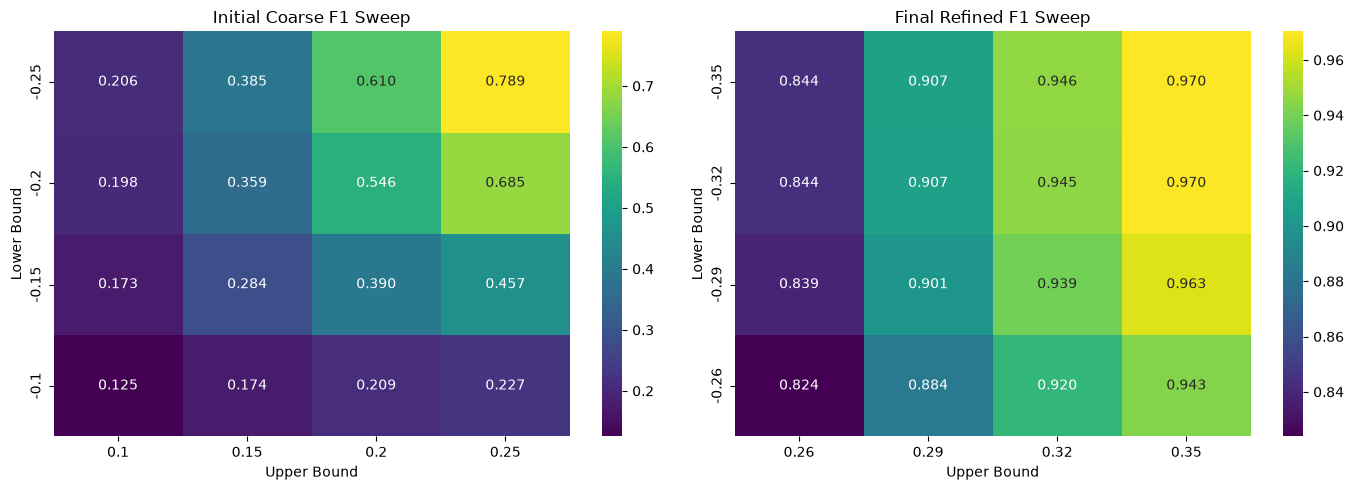

In [14]:
#Coarse data
coarse_pivot = coarse_table.pivot_table(index="lower", columns="upper", values="f1", aggfunc="max")
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.heatmap(coarse_pivot, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set_title("Initial Coarse F1 Sweep")
axes[0].set_xlabel("Upper Bound")
axes[0].set_ylabel("Lower Bound")

#Refined data
refined_pivot = refined_table.pivot_table(index="lower", columns="upper", values="f1", aggfunc="max")

sns.heatmap(refined_pivot, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("Final Refined F1 Sweep")
axes[1].set_xlabel("Upper Bound")
axes[1].set_ylabel("Lower Bound")

plt.tight_layout()
plt.show()

---

# Phase 6: Frozen Snapshot

Now that the sweep has done precisely what we needed, we can take a snapshot of the best parameters from our refined table and name them as constants.  Since everything from here on will pull from them, any changes made to the parameters can be made on these lines instead of hunting through the notebook to change parameters.

This also marks the inflection point in which we move from exploratory data refinement into full data specification.  This is the part that you would expect from a data analyst.


Frozen parameters: selected from the top row of the refined sweep in Phase  5


In [15]:
final_lower = -0.35
final_upper = 0.35
final_floor = 20

# Rebuild the detector sweep with the frozen snapshot

zero_mask = df["count_qty_current_year"] == 0
var_mask = (df["yoy_variance"] < final_lower) | (df["yoy_variance"] > final_upper)
floor_mask = (df["count_qty_prior_year"] + df["count_qty_current_year"]) >= final_floor

final_detector = zero_mask | (var_mask & floor_mask)

# Sanity checking the detector against the answer key to make sure the final detector reproduces the optimized row
final_metrics = detectionMetrics(answer_key, final_detector)
print(f"Snapshot metrics: P={final_metrics['precision']:.3f} | R={final_metrics['recall']:.3f} | F1={final_metrics['f1']:.3f}")
print(f"Flagged for investigation: {int(final_detector.sum()):,} of {len(df):,} rows")

# Create a separate data frame containing ONLY the flagged rows
flagged = df[final_detector].copy()

# Attach a reason to why each row was flagged, starting with zeros since they also trip the variance band.

flagged["flag_reason"] =np.where(
    zero_mask.reindex(flagged.index), "zero count", "variance band"
)

print(flagged["flag_reason"].value_counts().to_string())

Snapshot metrics: P=0.942 | R=1.000 | F1=0.970
Flagged for investigation: 2,447 of 154,000 rows
flag_reason
variance band    1992
zero count        455


---

# Phase 7: LLM Summarization

A flagged row is not exactly a find.  The detector tells us *which* rows need a physical count, not *what* to look for.  That is why we ping the LLM: to tell us the numbers into actionable sentences.

Three design choices matter here:

**Mock mode:**  if no API is present, the notebook runs the pipeline with deterministic stand-in text.  Anyone that clones the repo can run the entire notebook without a key, a billing account, or a network call.

**Batching:** sending thousands of individual requests is slow and token heavy.  Instead we send compact groups of rows and ask for a single JSON object (returned by row ID) so joining the data back is a lookup rather than a parsing exercise.

**Caching:** Explanations are written to the disk as they arrive.  Re-running the notebook is free and, more usefully, lets us iterate on the display of the output without rebilling for the text we already have.

This is also the only location in the notebook, other than Cell 1, that I am importing libraries.  This is to keep the API module together without cluttering the beginning of the notebook.

In [16]:
import os
import json
import time
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()
provider = os.environ.get("LLM_PROVIDER", "unset")
base_urls = {"LLM_BASE_URL"}
api_key = os.environ.get("LLM_API_KEY")
model = os.environ.get("LLM_MODEL", "gpt-4o-mini")

use_mock = not api_key

max_rows = 200
batch_size = 10

client = None
if not use_mock:
    from openai import OpenAI
    client = OpenAI(api_key=api_key, base_url=base_urls)

print(f"Mock mode (no LLM_API_KEY found)" if use_mock
      else f"Live mode: {provider} / {model}")



Mock mode (no LLM_API_KEY found)


In [17]:
def build_payload(row):
    var = row["yoy_variance"]
    return {
        "row_id": int(row.name),
        "sku": row["sku"],
        "location": row["location"],
        "period": row["period"],
        "prior_count": int(row["count_qty_prior_year"]),
        "current_count": int(row["count_qty_current_year"]),
        "yoy_variance_pct": round(float(var) * 100, 1) if pd.notna(var) else None,
        "flag_reason": row["flag_reason"],
    }

system_prompt = (
    "You are an inventory analyst assistant.  For each flagged cycle count row, write ONE plain English sentence (30 words max) explaining the most likely cause and what a warehouse associate would physically verify."
    "Reply with ONLY a JSON object mapping row_id (as a string) to that sentence.  No preamble, no markdown fences, no commentary."
)

In [18]:
def mock_explanations(batch):
    out = {}
    for _, row in batch.iterrows():
        prior = int(row["count_qty_prior_year"])
        current = int(row["count_qty_current_year"])
        var = row["yoy_variance"]
        
        if row["flag_reason"] == "zero count":
            text = (f"Count recorded as zero against {prior} units last year; verify the slot is not empty, mislabeled, or was simply skipped.")
        
        elif pd.notna(var) and var < 0:
            text = (f"Down {abs(var) * 100:.0f}% year over year ({prior} to {current}); check for unrecorded issues, misplacement, or receiving errors.")
        
        else:
            text = (f"Up {var * 100:.0f}% year over year ({prior} to {current}); suspect a duplicated digit, misplaced stock, or a keying error")
        
        out[str(int(row.name))] = text
    return out

def live_explanations(batch):
    payload = [build_payload(row) for _, row in batch.iterrows()]
    message = "Explain these flagged cycle count rows:\n" + json.dumps(payload)
    
    response = client.chat.completions.create(
        model=model,
        max_tokens=2000,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": message},
        ],
    )
    
    raw = response.choices[0].message.content.strip()
    
    if raw.startswith("```"):
        raw = raw.split("```")[1].removeprefix("json").strip()
    return json.loads(raw)

def explain_batch(batch, attempts=5):
    for attempt in range(1, attempts +1):
        try:
            return mock_explanations(batch) if use_mock else live_explanations(batch)
        except Exception as exc:
            status = getattr(exc, "status_code", None)
            if status and 400 <= status < 500 and status != 429:
                raise
            if attempt == attempts:
                raise
            wait = 2 ** attempt + np.random.uniform(0,1)
            print(f"attempt {attempt} failed ({type(exc).__name__}); retrying in {wait}s")
            time.sleep(wait)

In [19]:
cache_path = Path("explanation_cache.json")
cache = json.loads(cache_path.read_text()) if cache_path.exists() else {}

demo_rows = flagged.head(max_rows)
batches = [demo_rows.iloc[i:i + batch_size] for i in range(0, len(demo_rows), batch_size)]

print(f"Narrating {len(demo_rows):,} flagged rows in {len(batches)} batch(es)... \n")

for n, batch in enumerate(batches, 1):
    ids = [str(int(i)) for i in batch.index]
    missing = [i for i in ids if i not in cache]
    
    if missing:
        todo = batch.loc[[int(i) for i in missing]]
        cache.update(explain_batch(todo))
        cache_path.write_text(json.dumps(cache, indent=2))
    
    print(f"batch {n}/{len(batches)}: {len(missing)} new, {len(ids) - len(missing)} cached")

#Join narration back onto the flagged rows
flagged["explanation"] = flagged.index.astype(str).map(cache)
print(f"\nExplained {flagged['explanation'].notna().sum():,} of {len(flagged):,} flagged rows.")

Narrating 200 flagged rows in 20 batch(es)... 

batch 1/20: 10 new, 0 cached
batch 2/20: 10 new, 0 cached
batch 3/20: 10 new, 0 cached
batch 4/20: 10 new, 0 cached
batch 5/20: 10 new, 0 cached
batch 6/20: 10 new, 0 cached
batch 7/20: 10 new, 0 cached
batch 8/20: 10 new, 0 cached
batch 9/20: 10 new, 0 cached
batch 10/20: 10 new, 0 cached
batch 11/20: 10 new, 0 cached
batch 12/20: 10 new, 0 cached
batch 13/20: 10 new, 0 cached
batch 14/20: 10 new, 0 cached
batch 15/20: 10 new, 0 cached
batch 16/20: 10 new, 0 cached
batch 17/20: 10 new, 0 cached
batch 18/20: 10 new, 0 cached
batch 19/20: 10 new, 0 cached
batch 20/20: 10 new, 0 cached

Explained 200 of 2,447 flagged rows.


In [20]:
#peek at the output a warehouse associate would actually read

sample = flagged.loc[flagged["explanation"].notna(), ["sku", "location", "period", "count_qty_prior_year", "count_qty_current_year", "flag_reason", "explanation"]].head(5)

for _, r in sample.iterrows():
    print(f"{r['sku']} @ {r['location']} ({r['period']}) -- {r['count_qty_prior_year']} -> {r['count_qty_current_year']} [{r['flag_reason']}]")
    print(f"{r['explanation']}\n")

SKU-00001 @ STG-A (2025-01) -- 361 -> 4540 [variance band]
Up 1158% year over year (361 to 4540); suspect a duplicated digit, misplaced stock, or a keying error

SKU-00001 @ PICK-2 (2025-05) -- 428 -> 1360 [variance band]
Up 218% year over year (428 to 1360); suspect a duplicated digit, misplaced stock, or a keying error

SKU-00002 @ STG-A (2026-06) -- 417 -> 238 [variance band]
Down 43% year over year (417 to 238); check for unrecorded issues, misplacement, or receiving errors.

SKU-00002 @ PICK-1 (2026-09) -- 393 -> 164 [variance band]
Down 58% year over year (393 to 164); check for unrecorded issues, misplacement, or receiving errors.

SKU-00002 @ PICK-2 (2025-04) -- 415 -> 0 [zero count]
Count recorded as zero against 415 units last year; verify the slot is not empty, mislabeled, or was simply skipped.



---

# Phase 8: Export Data

Everything we have been working towards has been leading up to this.  Remember way back when?  When I was explaining the data generation and then the injection?  Those were simpler times.

I digress, everything prior to here has been the analysis: has something gone wrong?  Is this data that we can isolate?  What windows should we look at?  How does this get back to the warehouse?

This export is designed to be easy to read with one row per flagged location and an explanation.  The more we can simplify the data, the easier it is for the frontline employees so they don't have to sit around and parse what the data means.  That's what we're doing here.

A quick aside: due to keeping the payload to the LLM small for demonstration purposes, only the first "max_rows" number of rows carry the explanation in the explanation column.  Everything passed that will simply be blank.

In [21]:
export_path = Path("cycle_count_flags.csv")

export_cols = [
    "sku", "location", "period",
    "count_qty_prior_year", "count_qty_current_year",
    "yoy_variance", "flag_reason", "explanation",
]

flagged[export_cols].to_csv(export_path, index_label="row_id")

blank = int(flagged["explanation"].isna().sum())
print(f"Wrote {len(flagged):,} flagged rows to {export_path.resolve()}")
print(f"Rows carrying and explanation: {len(flagged) - blank:,} | awaiting narration: {blank:,}")
print(f"Columns: {', '.join(export_cols)}")

Wrote 2,447 flagged rows to C:\Users\donoh\OneDrive\Desktop\Python Projects\Warehouse_Data_Discrepancies\cycle_count_flags.csv
Rows carrying and explanation: 200 | awaiting narration: 2,247
Columns: sku, location, period, count_qty_prior_year, count_qty_current_year, yoy_variance, flag_reason, explanation
